<a href="https://colab.research.google.com/github/AlexXenpai/kalp-hastaligi-projesi/blob/main/heart-disease-uci/proje.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Heart Disease UCI: Kalp hastalığı var/yok sınıflandırması

Bu başlangıç seviyesi çalışmada doğrulanmış UCI Cleveland verisi kullanılır. `num` hedefi 0 ise hastalık yok, 1–4 ise hastalık var olarak ikili `disease` hedefine dönüştürülür. Pozitif sınıf `1 = hastalık var`dır. Bu notebook eğitim amaçlıdır; klinik tanı aracı değildir.

Hücreleri sırayla çalıştırın. `train.py` ile aynı yordamlar kullanıldığı için veri doğrulaması, öğrenme ve raporlar tekrarlanabilir.

In [2]:
from pathlib import Path
import subprocess
import sys
import os

klasor = Path("/content/kalp-projesi")

if not klasor.exists():
    subprocess.run([
        "git", "clone",
        "https://github.com/AlexXenpai/kalp-hastaligi-projesi.git",
        str(klasor)
    ], check=True)

os.chdir(klasor / "heart-disease-uci")

if str(Path.cwd()) not in sys.path:
    sys.path.insert(0, str(Path.cwd()))

print("Hazır, proje klasöründeyiz.")

fatal: destination path '/content/kalp-projesi' already exists and is not an empty directory.
/content/kalp-projesi/heart-disease-uci


In [3]:
from IPython.display import display, Markdown
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay
import train as proje

pd.set_option('display.max_columns', None)
raw = proje.load_data()
print('UCI Heart Disease — processed Cleveland (1988)')
print('Veri boyutu (satır, sütun):', raw.shape)
display(raw.head())
print('Veri tipleri:')
display(raw.dtypes.rename('veri_tipi').to_frame())
print('Özet istatistikler:')
display(raw.describe().T)

UCI Heart Disease — processed Cleveland (1988)
Veri boyutu (satır, sütun): (303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


Veri tipleri:


,veri_tipi
age,float64
sex,float64
cp,float64
trestbps,float64
chol,float64
fbs,float64
restecg,float64
thalach,float64
exang,float64
oldpeak,float64


Özet istatistikler:


,count,mean,std,min,25%,50%,75%,max
age,303.0,54.438944,9.038662,29.0,48.0,56.0,61.0,77.0
sex,303.0,0.679868,0.467299,0.0,0.0,1.0,1.0,1.0
cp,303.0,3.158416,0.960126,1.0,3.0,3.0,4.0,4.0
trestbps,303.0,131.689769,17.599748,94.0,120.0,130.0,140.0,200.0
chol,303.0,246.693069,51.776918,126.0,211.0,241.0,275.0,564.0
fbs,303.0,0.148515,0.356198,0.0,0.0,0.0,0.0,1.0
restecg,303.0,0.990099,0.994971,0.0,0.0,1.0,2.0,2.0
thalach,303.0,149.607261,22.875003,71.0,133.5,153.0,166.0,202.0
exang,303.0,0.326733,0.469794,0.0,0.0,0.0,1.0,1.0
oldpeak,303.0,1.039604,1.161075,0.0,0.0,0.8,1.6,6.2


## Sütunların anlamı

Aşağıdaki sözlük UCI Cleveland sürümündeki özellikleri, kategori kodlarını ve birimleri açıklar. `num` kaynak hedefidir; model girdisi değildir. `disease` ikili hedefidir.

In [4]:
display(pd.DataFrame(proje.DICTIONARY, columns=['Sütun', 'Anlam', 'Birim / kodlar', 'Tür']))

,Sütun,Anlam,Birim / kodlar,Tür
0,age,Yaş,yıl,Sayısal
1,sex,"Kaynakta kaydedilen cinsiyet: 0 kadın, 1 erkek",birimsiz,Kategorik
2,cp,"Göğüs ağrısı: 1 tipik anjina, 2 atipik anjina,...",birimsiz,Kategorik
3,trestbps,Hastaneye kabulde dinlenme kan basıncı,mmHg,Sayısal
4,chol,Serum kolesterolü,mg/dL,Sayısal
5,fbs,"Açlık kan şekeri >120 mg/dL mi? 0 hayır, 1 evet",birimsiz gösterge,Kategorik
6,restecg,"Dinlenme EKG: 0 normal, 1 ST-T anormalliği, 2 ...",birimsiz,Kategorik
7,thalach,Egzersiz testinde ulaşılan en yüksek kalp hızı,atım/dakika,Sayısal
8,exang,"Egzersizle oluşan anjina: 0 hayır, 1 evet",birimsiz,Kategorik
9,oldpeak,Egzersizin dinlenmeye göre oluşturduğu ST depr...,UCI belgesinde belirtilmemiş,Sayısal


## Temizleme ve sınıf dağılımı

`?` eksik değer belirteci olarak okunur. Kimlik alanları varsa çıkarılır; birebir tekrarlar değerlendirilir. Sayısal kodlu klinik kategoriler kategori olarak işlenir. Median ve en sık değer doldurucuları yalnızca eğitim fold'larında Pipeline tarafından öğrenilecektir.

In [5]:
df, audit = proje.clean_data(raw)
print('Ham veri / temiz veri boyutları:', audit['raw_shape'], '/', audit['clean_shape'])
print('Temizleme denetimi:')
display(pd.Series(audit, name='değer').to_frame())
print('Özgün num hedefinin sınıf sayıları:')
display(pd.Series(audit['original_target_counts'], name='kayıt_sayısı').rename_axis('num').to_frame())
print('İkili hedef dağılımı:')
display(proje.class_table(df['disease']))
display(Markdown('Sınıfların sayıları ve yüzdeleri yukarıda, gerçek veriden hesaplanmıştır. Sınıf oranları eşit değilse accuracy tek başına yeterli değildir; özellikle hastalık var sınıfının recall değeri de izlenmelidir.'))

Ham veri / temiz veri boyutları: [303, 14] / [303, 15]
Temizleme denetimi:


,değer
raw_shape,"[303, 14]"
clean_shape,"[303, 15]"
removed_id_columns,[]
exact_duplicates_removed,0
missing_counts,"{'age': 0, 'sex': 0, 'cp': 0, 'trestbps': 0, '..."
question_marks,6
original_target_counts,"{0: 164, 1: 55, 2: 36, 3: 35, 4: 13}"


Özgün num hedefinin sınıf sayıları:


,kayıt_sayısı
num,
0,164
1,55
2,36
3,35
4,13


İkili hedef dağılımı:


,Sınıf,Sayı,Yüzde
0,Hayır — hastalık yok,164,54.13
1,Evet — hastalık var,139,45.87


Sınıfların sayıları ve yüzdeleri yukarıda, gerçek veriden hesaplanmıştır. Sınıf oranları eşit değilse accuracy tek başına yeterli değildir; özellikle hastalık var sınıfının recall değeri de izlenmelidir.

## Eğitim/test ayrımı ve model karşılaştırması

Veri %80 eğitim, %20 test olarak `stratify` ve `random_state=42` ile ayrılır. Model seçimi sadece eğitim verisinde beş katlı StratifiedKFold sonuçlarıyla yapılır. Pozitif recall önceliklidir; eşitlikte precision ve sonra F1 ile sıralama yapılır. Test kümesi bu aşamada kullanılmaz.

In [6]:
X_train, X_test, y_train, y_test = proje.split_data(df)
print(f'Eğitim: {len(X_train)} kayıt (%{len(X_train) / len(df) * 100:.1f}); test: {len(X_test)} kayıt (%{len(X_test) / len(df) * 100:.1f})')
cv_table, selected_name, pipeline = proje.compare_models(X_train, y_train)
print('Eğitim verisinde 5-fold StratifiedKFold karşılaştırması (ortalama ± standart sapma):')
display(cv_table)
print('Seçilen model:', selected_name)
display(Markdown('Model yalnızca eğitim kümesindeki ortalama hastalık-pozitif recall değerine göre seçildi; recall eşitliğinde precision, ardından F1 kullanıldı. Daha yüksek recall daha az hastalık vakasını kaçırmayı hedefler, fakat precision düşebilir ve daha çok yanlış pozitif oluşabilir. Eşik 0.5 olarak sabittir.'))

Eğitim: 242 kayıt (%79.9); test: 61 kayıt (%20.1)
Eğitim verisinde 5-fold StratifiedKFold karşılaştırması (ortalama ± standart sapma):


,model,accuracy_mean,accuracy_std,precision_mean,precision_std,recall_mean,recall_std,f1_mean,f1_std
0,Logistic Regression,0.847024,0.024144,0.878326,0.079267,0.783794,0.037695,0.825353,0.016813
1,Random Forest,0.809779,0.018927,0.809659,0.050569,0.773913,0.086648,0.787035,0.031701
2,Decision Tree,0.743878,0.039867,0.734418,0.062153,0.701581,0.096767,0.713545,0.053224


Seçilen model: Logistic Regression


Model yalnızca eğitim kümesindeki ortalama hastalık-pozitif recall değerine göre seçildi; recall eşitliğinde precision, ardından F1 kullanıldı. Daha yüksek recall daha az hastalık vakasını kaçırmayı hedefler, fakat precision düşebilir ve daha çok yanlış pozitif oluşabilir. Eşik 0.5 olarak sabittir.

## Görselleştirmeler

Aşağıdaki grafikler yalnızca eğitim kümesinden üretilir. Her grafiğin hemen ardından, bu veri kümesinde hesaplanan sayılara dayalı kısa yorum gösterilir. Gözlenen ilişkiler nedensellik anlamına gelmez.

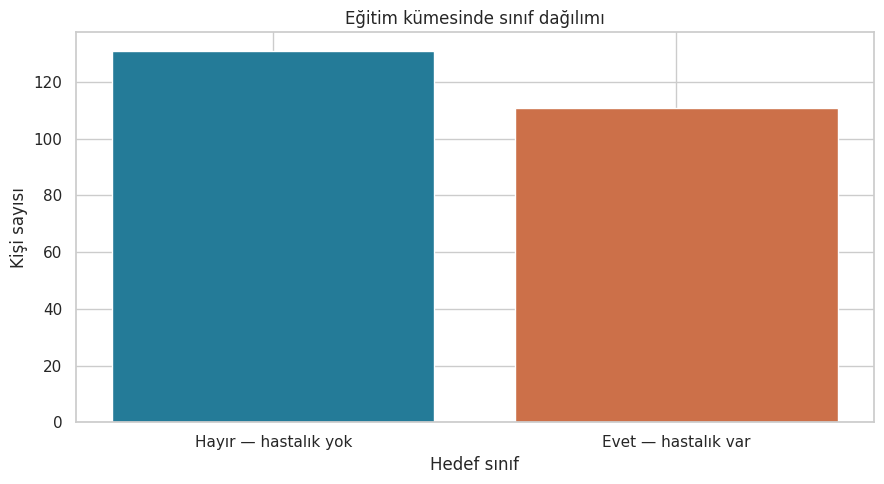

**Veriye dayalı yorum:** Hayır: 131 (%54.1); evet: 111 (%45.9). Sınıflar tam eşit değildir; accuracy tek başına yeterli değildir.

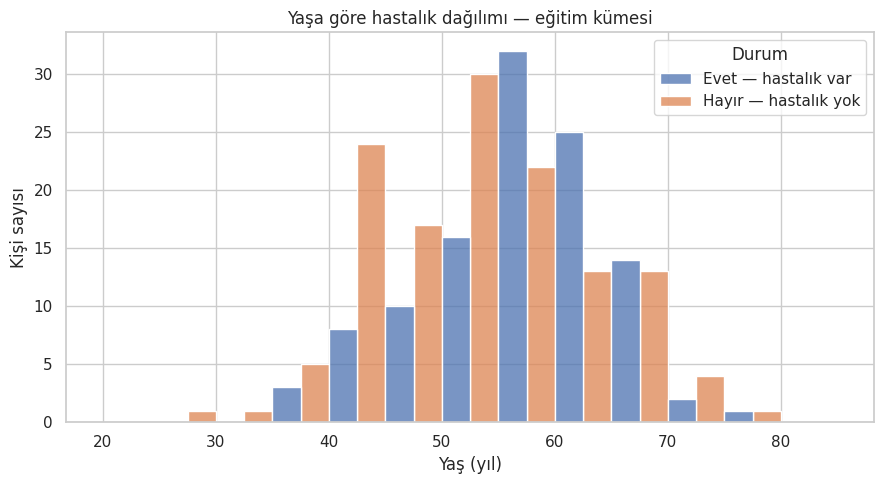

**Veriye dayalı yorum:** Medyan yaş hastalık yok grubunda 52.0, hastalık var grubunda 58.0. Yaş dağılımları örtüşür; yaş tek başına bir tanı ölçütü değildir.

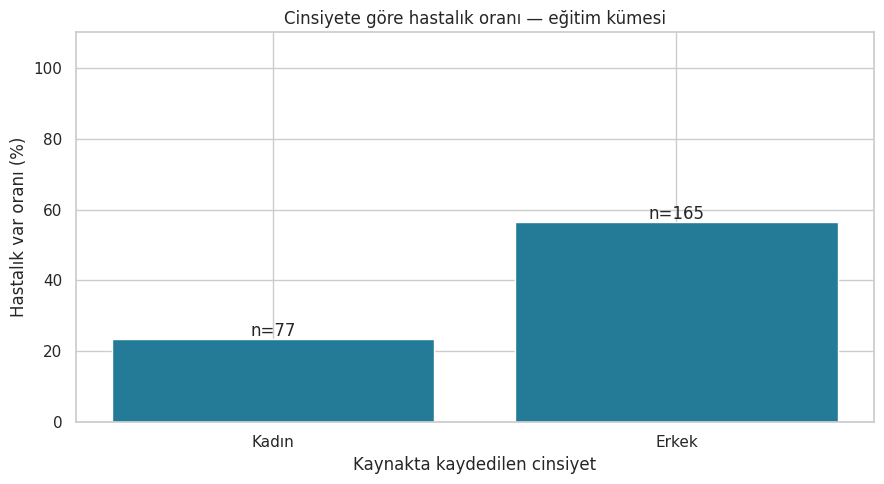

**Veriye dayalı yorum:** Kadın: %23.4 (n=77); Erkek: %56.4 (n=165). Bunlar bu örneklemdeki oranlardır; grupların büyüklükleri farklıdır ve neden-sonuç göstermez.

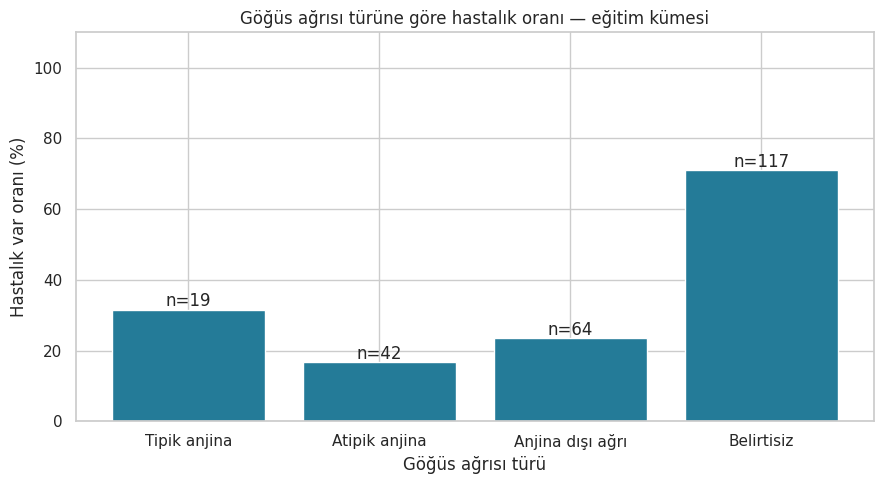

**Veriye dayalı yorum:** Tipik anjina: %31.6 (n=19); Atipik anjina: %16.7 (n=42); Anjina dışı ağrı: %23.4 (n=64); Belirtisiz: %70.9 (n=117). Bunlar bu örneklemdeki oranlardır; grupların büyüklükleri farklıdır ve neden-sonuç göstermez.

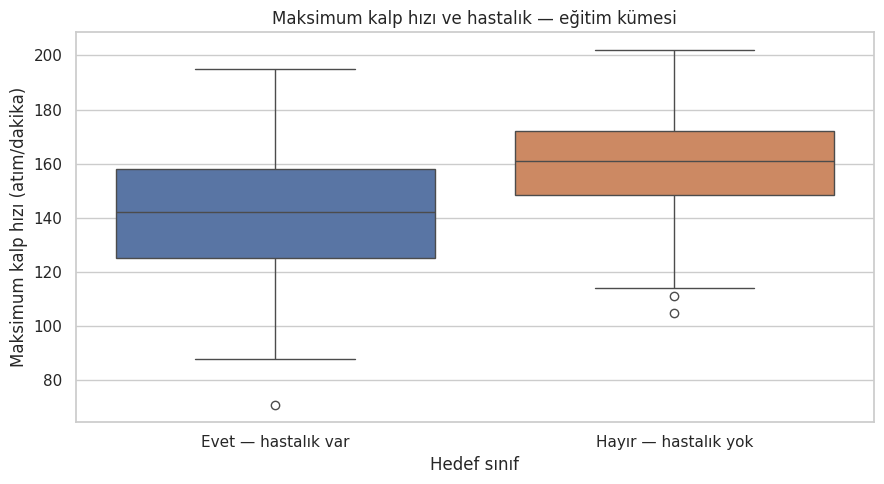

**Veriye dayalı yorum:** Maksimum kalp hızı medyanı hayır grubunda 161.0, evet grubunda 142.0 atım/dakika. Bu fark tek bir kişide güvenilir tanı sağlamaz ve nedensellik göstermez.

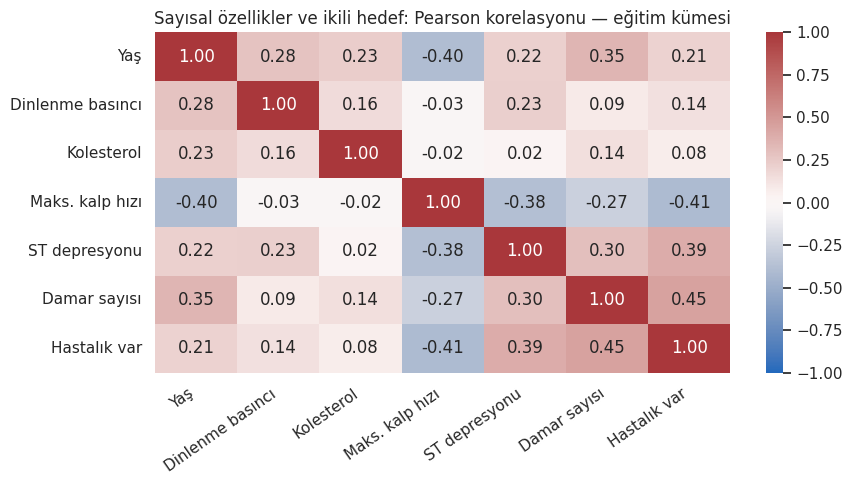

**Veriye dayalı yorum:** Hedefle mutlak Pearson korelasyonu en yüksek sayısal özellik Damar sayısı (r=0.45). Kategorik kodlar ısı haritasına alınmadı. Eksikler çiftler bazında dışlandı; korelasyon nedensellik veya doğrusal olmayan tüm ilişkiler değildir.

In [7]:
train_df = X_train.assign(disease=y_train)
for kind in ['hedef', 'yas', 'cinsiyet', 'agri', 'nabiz', 'korelasyon']:
    fig, comment = proje.draw_plot(kind, train_df)
    display(fig)
    display(Markdown('**Veriye dayalı yorum:** ' + comment))
    plt.close(fig)

## Son test değerlendirmesi

Seçim tamamlandıktan sonra test kümesi bir kez son değerlendirme için kullanılır. Pozitif sınıf `1 = hastalık var`dır. Confusion matrix satırları gerçek, sütunları tahmin etiketidir.

Seçilen model: Logistic Regression | pozitif sınıf: 1 = hastalık var


,test_değeri
Accuracy,0.868852
Precision,0.812500
Recall (hastalık var),0.928571
F1-score,0.866667


Confusion matrix — satırlar gerçek, sütunlar tahmin:


,Tahmin hayır,Tahmin evet
Gerçek hayır,27,6
Gerçek evet,2,26


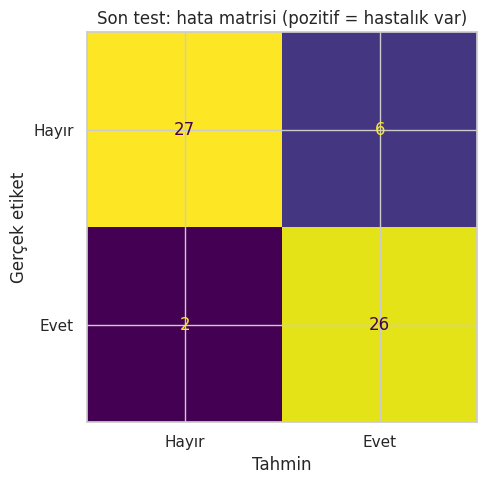

Classification report:
                      precision    recall  f1-score   support

Hayır — hastalık yok       0.93      0.82      0.87        33
 Evet — hastalık var       0.81      0.93      0.87        28

            accuracy                           0.87        61
           macro avg       0.87      0.87      0.87        61
        weighted avg       0.88      0.87      0.87        61



In [8]:
metrics, report, matrix, errors = proje.evaluate_final(pipeline, X_test, y_test, X_train)
print('Seçilen model:', selected_name, '| pozitif sınıf: 1 = hastalık var')
display(pd.Series(metrics, name='test_değeri').rename(index={
    'accuracy': 'Accuracy', 'precision': 'Precision', 'recall': 'Recall (hastalık var)', 'f1': 'F1-score'
}).to_frame())
print('Confusion matrix — satırlar gerçek, sütunlar tahmin:')
display(pd.DataFrame(matrix, index=['Gerçek hayır', 'Gerçek evet'], columns=['Tahmin hayır', 'Tahmin evet']))
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(matrix, display_labels=['Hayır', 'Evet']).plot(ax=ax, colorbar=False)
ax.set(xlabel='Tahmin', ylabel='Gerçek etiket', title='Son test: hata matrisi (pozitif = hastalık var)')
fig.tight_layout()
display(fig)
plt.close(fig)
print('Classification report:')
print(report)

### Yanlış tahmin örnekleri ve hata türleri

False negative (yanlış negatif), hastalık gerçekte varken modelin “hastalık yok” demesidir; tıbbi değerlendirmenin gecikmesi riski nedeniyle genellikle daha ciddi sonuçlar doğurabilir. False positive (yanlış pozitif), hastalık yokken “hastalık var” demesidir ve gereksiz kaygı veya ileri incelemeye neden olabilir. Aşağıdaki olası açıklamalar yalnızca gözlemlenebilir özelliklere dayalı ipuçlarıdır; modelin neden yanıldığını kesin olarak kanıtlamaz.

In [9]:
if errors.empty:
    print('Test kümesinde yanlış tahmin yok.')
else:
    display(errors)
    print('Yanlış tahmin sayısı:', int((pipeline.predict(X_test) != y_test).sum()), '| tabloda en fazla 5 örnek gösterilir.')
print('Bu proje eğitim amaçlıdır; model, olasılıkları ve hata örnekleri klinik tanı veya doğrulanmış tıbbi risk tahmini değildir.')
proje.save_results(pipeline, cv_table, selected_name, metrics, report, matrix, errors, audit, X_train, X_test, y_train, y_test)
print('Pipeline ve raporlar artifacts/ ile reports/ klasörlerine kaydedildi.')

,csv_satırı,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,gerçek,tahmin,P(hastalık_var),hata_türü,olası_açıklama
271,273,66.0,1.0,4.0,160.0,228.0,0.0,2.0,138.0,0.0,2.3,1.0,0.0,6.0,Hayır — hastalık yok,Evet — hastalık var,0.581286,False positive,Model skoru 0.5 karar eşiğine yakın; küçük değ...
196,198,69.0,1.0,1.0,160.0,234.0,1.0,2.0,131.0,0.0,0.1,2.0,1.0,3.0,Hayır — hastalık yok,Evet — hastalık var,0.560203,False positive,Model skoru 0.5 karar eşiğine yakın; küçük değ...
33,35,59.0,1.0,4.0,135.0,234.0,0.0,0.0,161.0,0.0,0.5,2.0,0.0,7.0,Hayır — hastalık yok,Evet — hastalık var,0.734141,False positive,"Maksimum kalp hızı 161, eğitim medyanı 153.5 d..."
179,181,53.0,1.0,3.0,130.0,246.0,1.0,2.0,173.0,0.0,0.0,1.0,3.0,3.0,Hayır — hastalık yok,Evet — hastalık var,0.690705,False positive,"Maksimum kalp hızı 173, eğitim medyanı 153.5 d..."
287,289,58.0,1.0,2.0,125.0,220.0,0.0,0.0,144.0,0.0,0.4,2.0,NaN,7.0,Hayır — hastalık yok,Evet — hastalık var,0.555165,False positive,Eksik ölçümler eğitim verisindeki değerlerle d...


Yanlış tahmin sayısı: 8 | tabloda en fazla 5 örnek gösterilir.
Bu proje eğitim amaçlıdır; model, olasılıkları ve hata örnekleri klinik tanı veya doğrulanmış tıbbi risk tahmini değildir.
Pipeline ve raporlar artifacts/ ile reports/ klasörlerine kaydedildi.
